<div style="color: green; text-align: center; font-size: 3em;">
    <strong>Desafío - Enfermedad en la sangre 😌🩸</strong>
</div>

En este desafío utilizaremos una base de datos recolectada en un laboratorio de donación
de sangre, en la que contamos con información de diferentes mediciones incluido el sexo
del donador y un indicador de donador sospechoso. Las variables regresoras son:

1. X (Patient ID/No.): Número o identificación única asociada a cada paciente en la
base de datos.

2. Category (diagnosis): Categoría que indica el diagnóstico relacionado con la
hepatitis C para cada paciente.

3. Age (in years): Edad del paciente en años al momento de la detección o registro en
la base de datos.

4. Sex (f,m): Género del paciente, indicado por "f" para femenino y "m" para masculino.

5. ALB: Albúmina, una proteína producida por el hígado. Los niveles de albúmina
pueden indicar la función hepática.

6. ALP: Fosfatasa alcalina, una enzima que puede estar relacionada con la función
hepática y otros procesos.

7. ALT: Alanina aminotransferasa, una enzima que puede indicar daño hepático.

8. AST: Aspartato aminotransferasa, una enzima que también puede indicar daño
hepático.

9. BIL: Bilirrubina, un pigmento amarillo que puede aumentar en casos de problemas
hepáticos.

10. CHE: Colinesterasa, una enzima que puede estar asociada con la función hepática y
otros procesos.

11. CHOL: Colesterol, un lípido que puede estar relacionado con la salud del hígado.

12. CREA: Creatinina, un producto de desecho que se filtra a través de los riñones.

13. GGT: Gamma-glutamil transferasa, una enzima que puede estar relacionada con la
función hepática.

14. PROT: Proteínas totales, que pueden incluir varias proteínas, como albúmina y
globulinas.

La variable objetivo es Category, y almacena las siguientes categorías: ‘0=Blood Donor',
'0s=suspect Blood Donor', '1=Hepatitis', '2=Fibrosis', '3=Cirrhosis’

#### Aplicando los conceptos y herramientas aprendidas hasta ahora, deberás realizar las siguientes tareas:

### 1. Importa las librerías necesarias para entrenar modelos de regresión logística con validación cruzada y Extreme Gradient Boosting, carga los datos y prepáralos. Para ello:

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
import xgboost as xgb

from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score


df = pd.read_csv('hcvdat0.csv')
df.head()

,Unnamed: 0,Category,Age,Sex,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT
0,1,0=Blood Donor,32,m,38.5,52.5,7.7,22.1,7.5,6.93,3.23,106.0,12.1,69.0
1,2,0=Blood Donor,32,m,38.5,70.3,18.0,24.7,3.9,11.17,4.80,74.0,15.6,76.5
2,3,0=Blood Donor,32,m,46.9,74.7,36.2,52.6,6.1,8.84,5.20,86.0,33.2,79.3
3,4,0=Blood Donor,32,m,43.2,52.0,30.6,22.6,18.9,7.33,4.74,80.0,33.8,75.7
4,5,0=Blood Donor,32,m,39.2,74.1,32.6,24.8,9.6,9.15,4.32,76.0,29.9,68.7


#### a. elimina la columna ‘Unnamed: 0’.

In [9]:
# Eliminar la columna "Unnamed: 0"
df = df.drop('Unnamed: 0', axis=1)
df.head()

,Category,Age,Sex,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT
0,0=Blood Donor,32,m,38.5,52.5,7.7,22.1,7.5,6.93,3.23,106.0,12.1,69.0
1,0=Blood Donor,32,m,38.5,70.3,18.0,24.7,3.9,11.17,4.80,74.0,15.6,76.5
2,0=Blood Donor,32,m,46.9,74.7,36.2,52.6,6.1,8.84,5.20,86.0,33.2,79.3
3,0=Blood Donor,32,m,43.2,52.0,30.6,22.6,18.9,7.33,4.74,80.0,33.8,75.7
4,0=Blood Donor,32,m,39.2,74.1,32.6,24.8,9.6,9.15,4.32,76.0,29.9,68.7


#### b. codifica la variable objetivo Category en dos categorías: una para Category=’0=Blood Donor’, a la que debes asociar valor 0, y un 1 para los demás valores. Asigna estos valores en una nueva columna llamada target.

In [10]:
# Codificar la variable objetivo 'Category' en dos categorías
df['target'] = df['Category'].apply(lambda x: 0 if x == '0=Blood Donor' else 1)

# Mostrar las primeras filas del DataFrame para verificar la nueva columna 'target'
df.head()


,Category,Age,Sex,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT,target
0,0=Blood Donor,32,m,38.5,52.5,7.7,22.1,7.5,6.93,3.23,106.0,12.1,69.0,0
1,0=Blood Donor,32,m,38.5,70.3,18.0,24.7,3.9,11.17,4.80,74.0,15.6,76.5,0
2,0=Blood Donor,32,m,46.9,74.7,36.2,52.6,6.1,8.84,5.20,86.0,33.2,79.3,0
3,0=Blood Donor,32,m,43.2,52.0,30.6,22.6,18.9,7.33,4.74,80.0,33.8,75.7,0
4,0=Blood Donor,32,m,39.2,74.1,32.6,24.8,9.6,9.15,4.32,76.0,29.9,68.7,0


#### c. codifica en otra columna, con nombre suspect, con valor 1 cuando Category=’0s=suspect Blood Donor’, y aigna 0 en caso contrario. Elimina finalmente la columna Category.

In [11]:
# Codificar la columna 'suspect' en función de la categoría '0s=suspect Blood Donor'
df['suspect'] = df['Category'].apply(lambda x: 1 if x == '0s=suspect Blood Donor' else 0)

# Eliminar la columna 'Category'
df.drop(columns=['Category'], inplace=True)

# Mostrar las primeras filas del DataFrame para verificar los cambios
df.head()


,Age,Sex,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT,target,suspect
0,32,m,38.5,52.5,7.7,22.1,7.5,6.93,3.23,106.0,12.1,69.0,0,0
1,32,m,38.5,70.3,18.0,24.7,3.9,11.17,4.80,74.0,15.6,76.5,0,0
2,32,m,46.9,74.7,36.2,52.6,6.1,8.84,5.20,86.0,33.2,79.3,0,0
3,32,m,43.2,52.0,30.6,22.6,18.9,7.33,4.74,80.0,33.8,75.7,0,0
4,32,m,39.2,74.1,32.6,24.8,9.6,9.15,4.32,76.0,29.9,68.7,0,0


#### d. Revisa si la base de datos contiene valores ausentes. En caso que sea así, aplica los siguientes criterios:

i. si el porcentaje de valores ausentes para alguna variable es menor a 1%, entonces elimina las filas que contengan estos valores ausentes

ii. si el porcentaje de valores ausentes es mayor, entonces reemplaza
estos por el promedio según la clase a la que pertenezca el valor
ausente

In [12]:
# Verificar valores ausentes en el DataFrame
missing_values = df.isnull().mean() * 100

# Identificar variables con valores ausentes
variables_with_missing = missing_values[missing_values > 0]

# Separar las variables con menos del 1% de valores ausentes y aquellas con más del 1%
less_than_1_percent = variables_with_missing[variables_with_missing < 1]
greater_than_1_percent = variables_with_missing[variables_with_missing >= 1]

# Eliminar filas con valores ausentes para variables con menos del 1%
if not less_than_1_percent.empty:
    df.dropna(subset=less_than_1_percent.index, inplace=True)

# Reemplazar valores ausentes por el promedio de la clase (según la columna 'target')
for col in greater_than_1_percent.index:
    df[col] = df.groupby('target')[col].transform(lambda x: x.fillna(x.mean()))

# Verificar si quedan valores ausentes
missing_values_after = df.isnull().sum()

# Mostrar la información actualizada del DataFrame
missing_values_after


Age        0
Sex        0
ALB        0
ALP        0
ALT        0
AST        0
BIL        0
CHE        0
CHOL       0
CREA       0
GGT        0
PROT       0
target     0
suspect    0
dtype: int64

#### e. Realiza un análisis descriptivo para cada variable regresora, usando gráficos para representar distribuciones y boxplot para revisar posibles outliers.
#### Construye un heatmap que muestre las correlaciones entre las variables regresoras y describe.

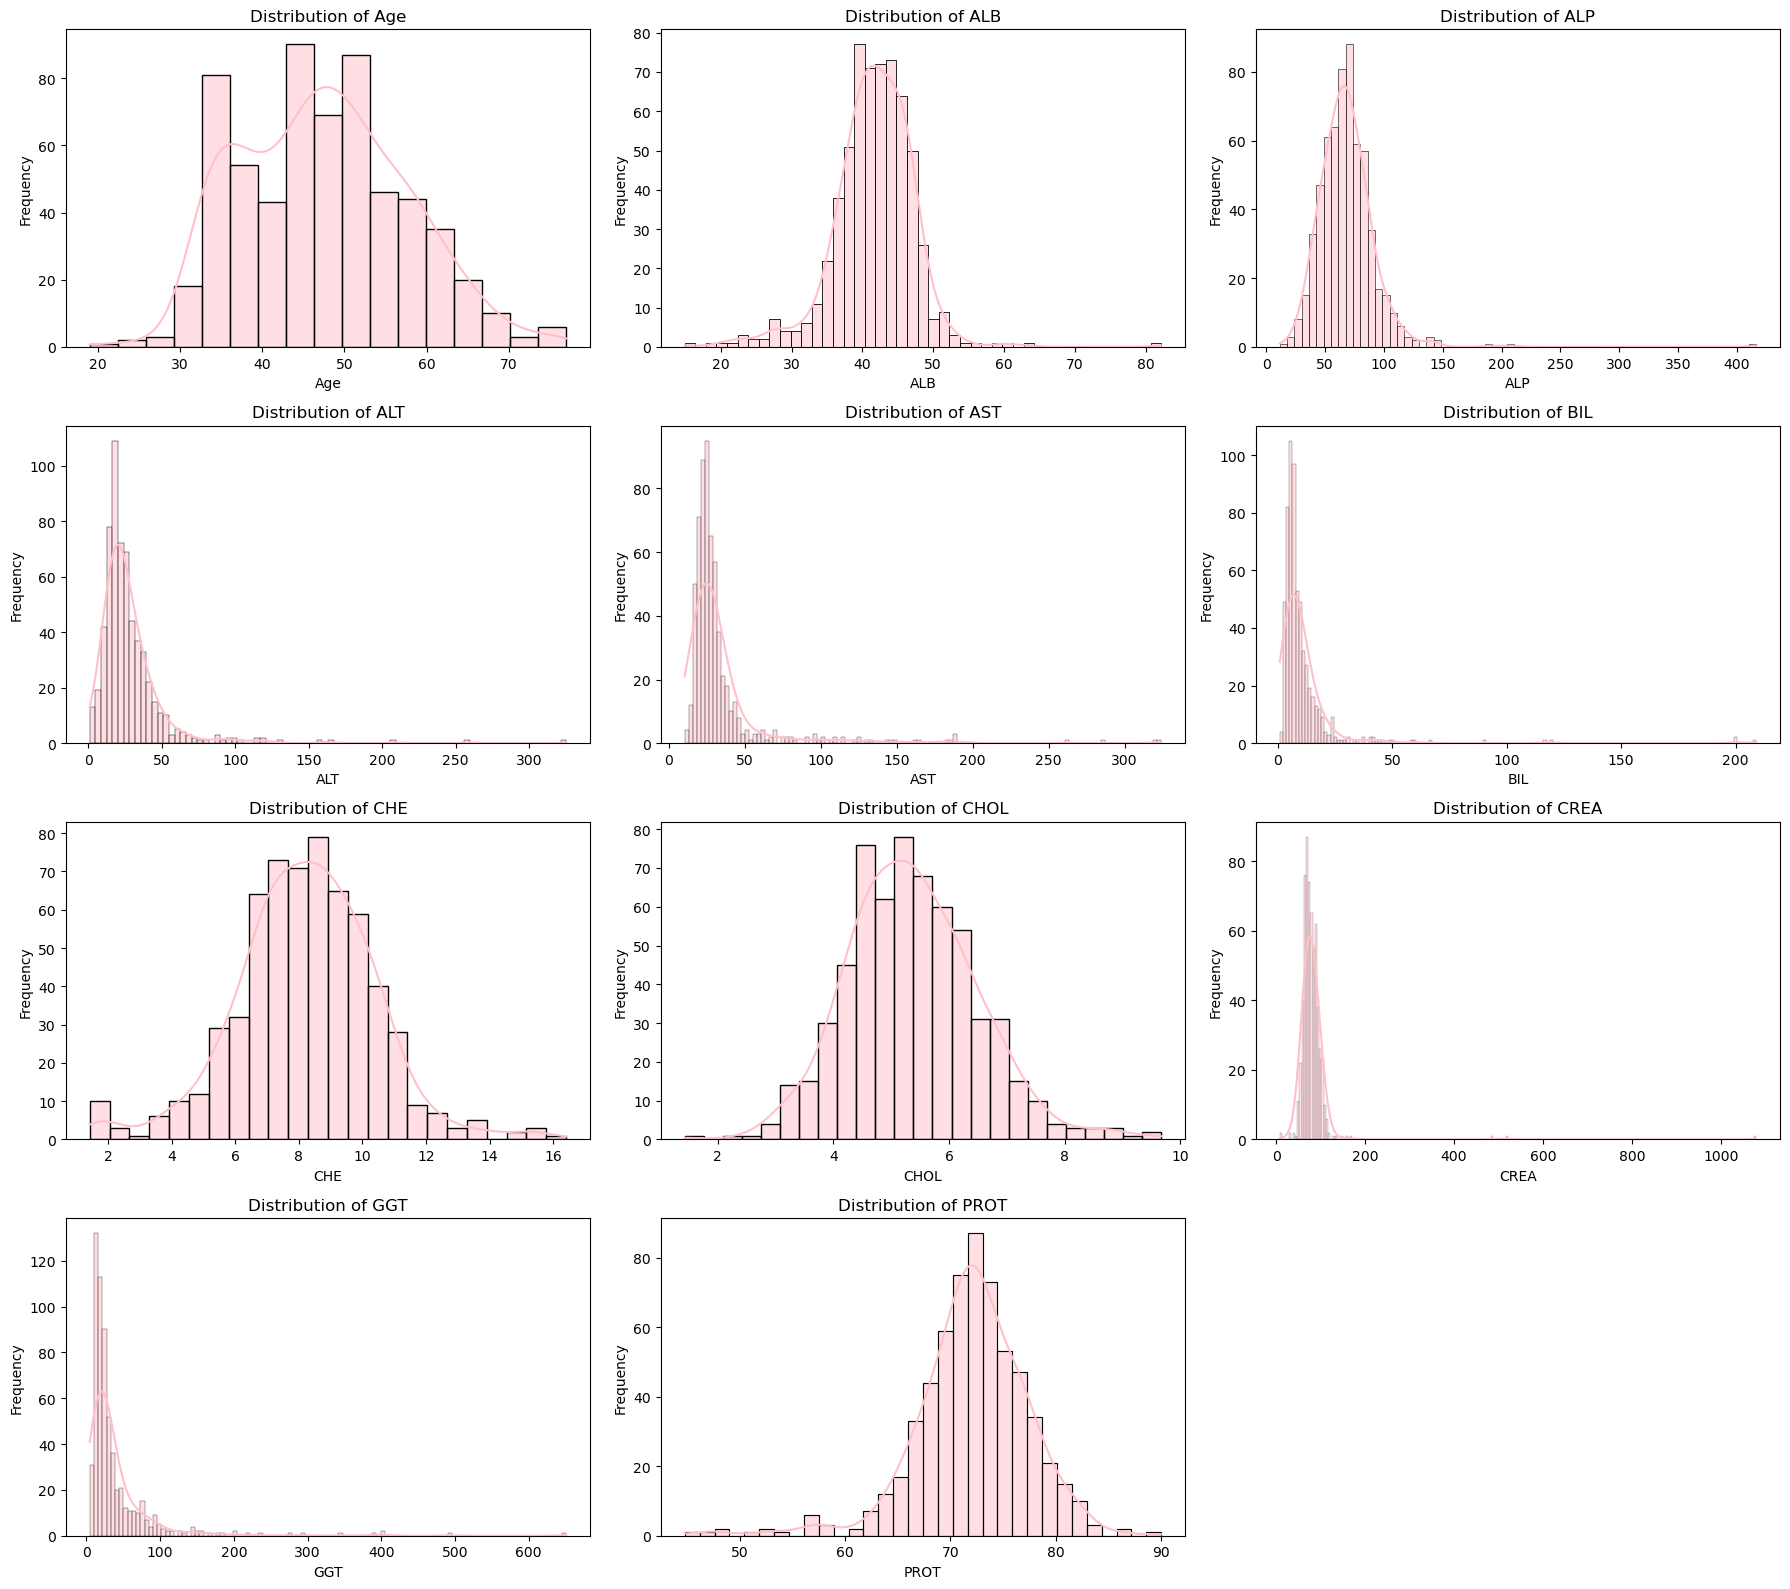

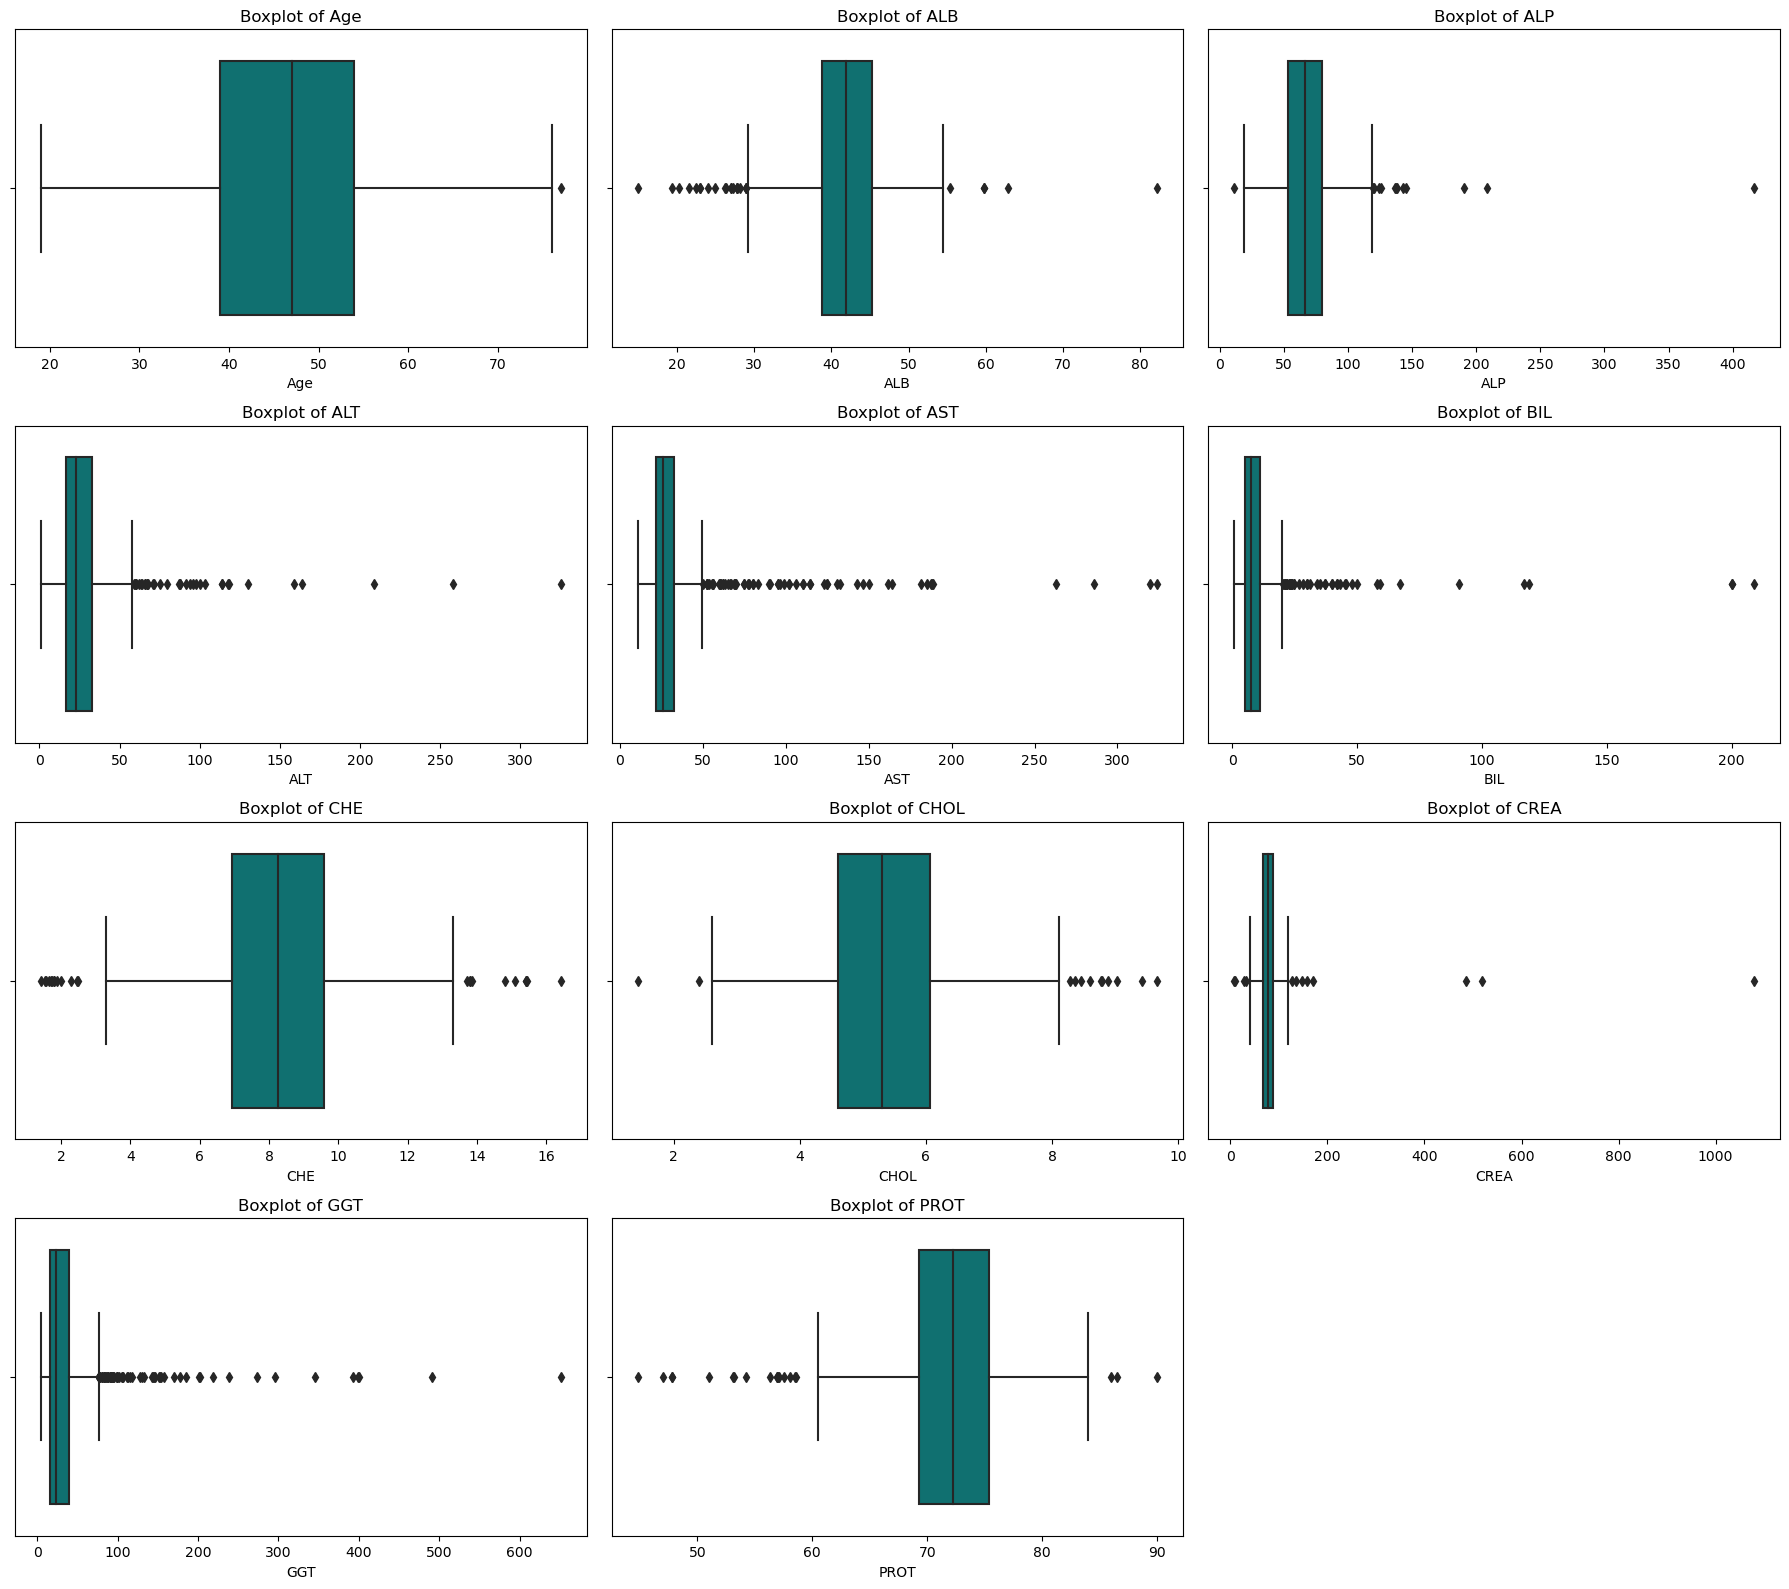

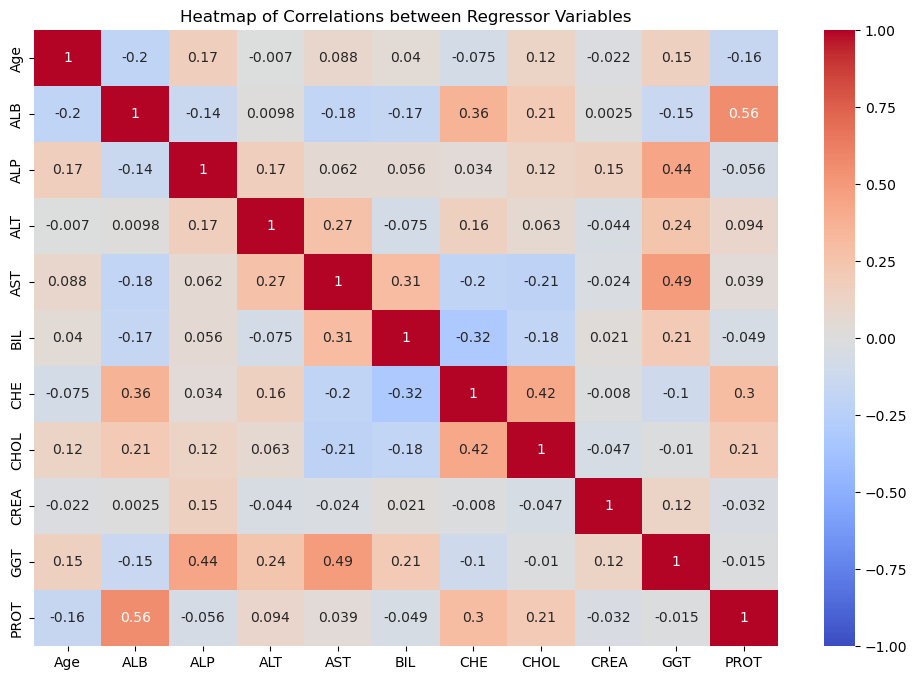

In [18]:

# Definir las variables regresoras
regressor_vars = df.drop(columns=['target', 'suspect', 'Sex'])

# Calcular el número de filas necesarias para la grilla (3 columnas)
num_vars = len(regressor_vars.columns)
num_rows = math.ceil(num_vars / 3)

# Crear gráficos de distribución en una grilla de 3 columnas
fig, axes = plt.subplots(num_rows, 3, figsize=(18, 4 * num_rows))
axes = axes.flatten()

for i, col in enumerate(regressor_vars.columns):
    sns.histplot(df[col], kde=True, ax=axes[i], color='pink')
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequency')

# Remover subplots vacíos
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

# Crear boxplots en una grilla de 3 columnas
fig, axes = plt.subplots(num_rows, 3, figsize=(18, 4 * num_rows))
axes = axes.flatten()

for i, col in enumerate(regressor_vars.columns):
    sns.boxplot(data=regressor_vars, x=col, ax=axes[i], color='teal')
    axes[i].set_title(f'Boxplot of {col}')
    axes[i].set_xlabel(col)

# Remover subplots vacíos
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

# Crear un heatmap de correlaciones entre las variables regresoras
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Heatmap of Correlations between Regressor Variables')
plt.show()

<div style="color: purple; font-size: 1em;">

Las variables en el conjunto de datos muestran diferentes patrones de distribución. Algunas, como ALB, CHE, y PROT, son más simétricas y centradas, mientras que otras, como ALT, AST, BIL, y GGT, están sesgadas hacia la derecha, lo cual es común en datos médicos. Además, variables como CREA y CHOL tienen varios picos, lo que podría indicar la presencia de diferentes grupos en la muestra o mediciones fuera de lo normal.

Los boxplots muestran que muchas variables, especialmente ALT, AST, BIL, y GGT, tienen varios outliers. Esto se debe a que en datos biológicos es común encontrar valores extremos, como en pacientes con enfermedades avanzadas. Algunas variables, como ALB y PROT, tienen un rango más estrecho, lo que indica menos variabilidad, a diferencia de ALT y GGT, que tienen rangos más amplios.

El heatmap de correlación revela relaciones fuertes entre algunas variables, como ALT y AST, lo cual es lógico, ya que ambas son enzimas hepáticas. También hay correlación moderada entre ALB y PROT. Sin embargo, la mayoría de las variables tienen correlaciones bajas entre sí, lo que sugiere que cada una aporta información única al modelo. Variables como CHOL, CREA, y BIL casi no se correlacionan con otras, lo que las hace potencialmente valiosas para el análisis.
</div>

#### f. Transforma las variables regresoras por medio de la estandarización.
#### Muestra el antes y después de esta usando boxplots, y realiza una segmentación de la muestra en 33% para test y el resto para entrenamien

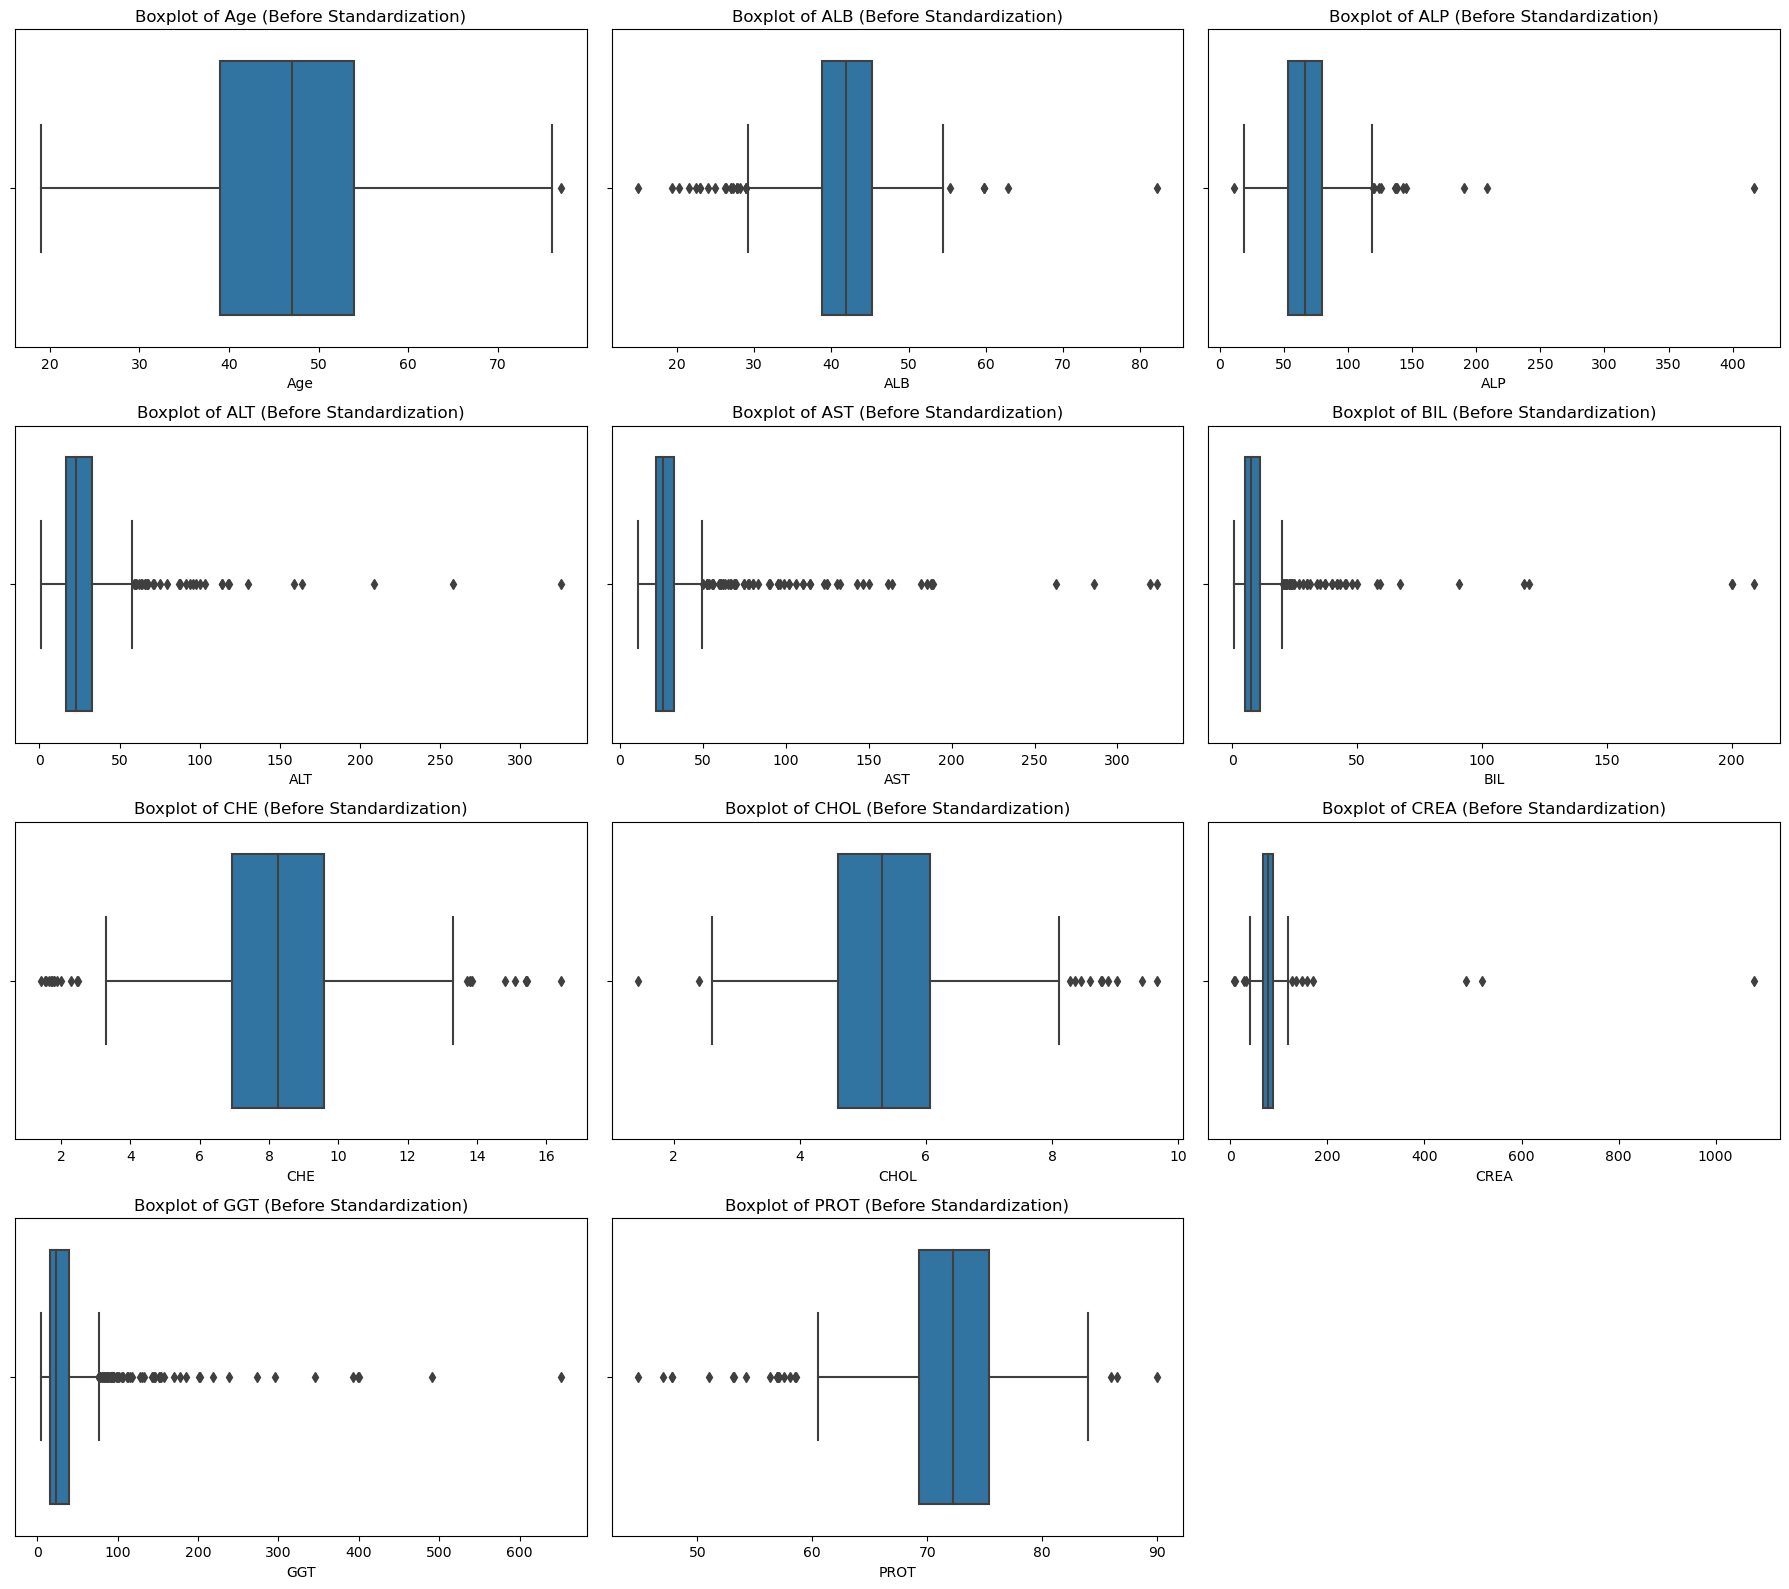

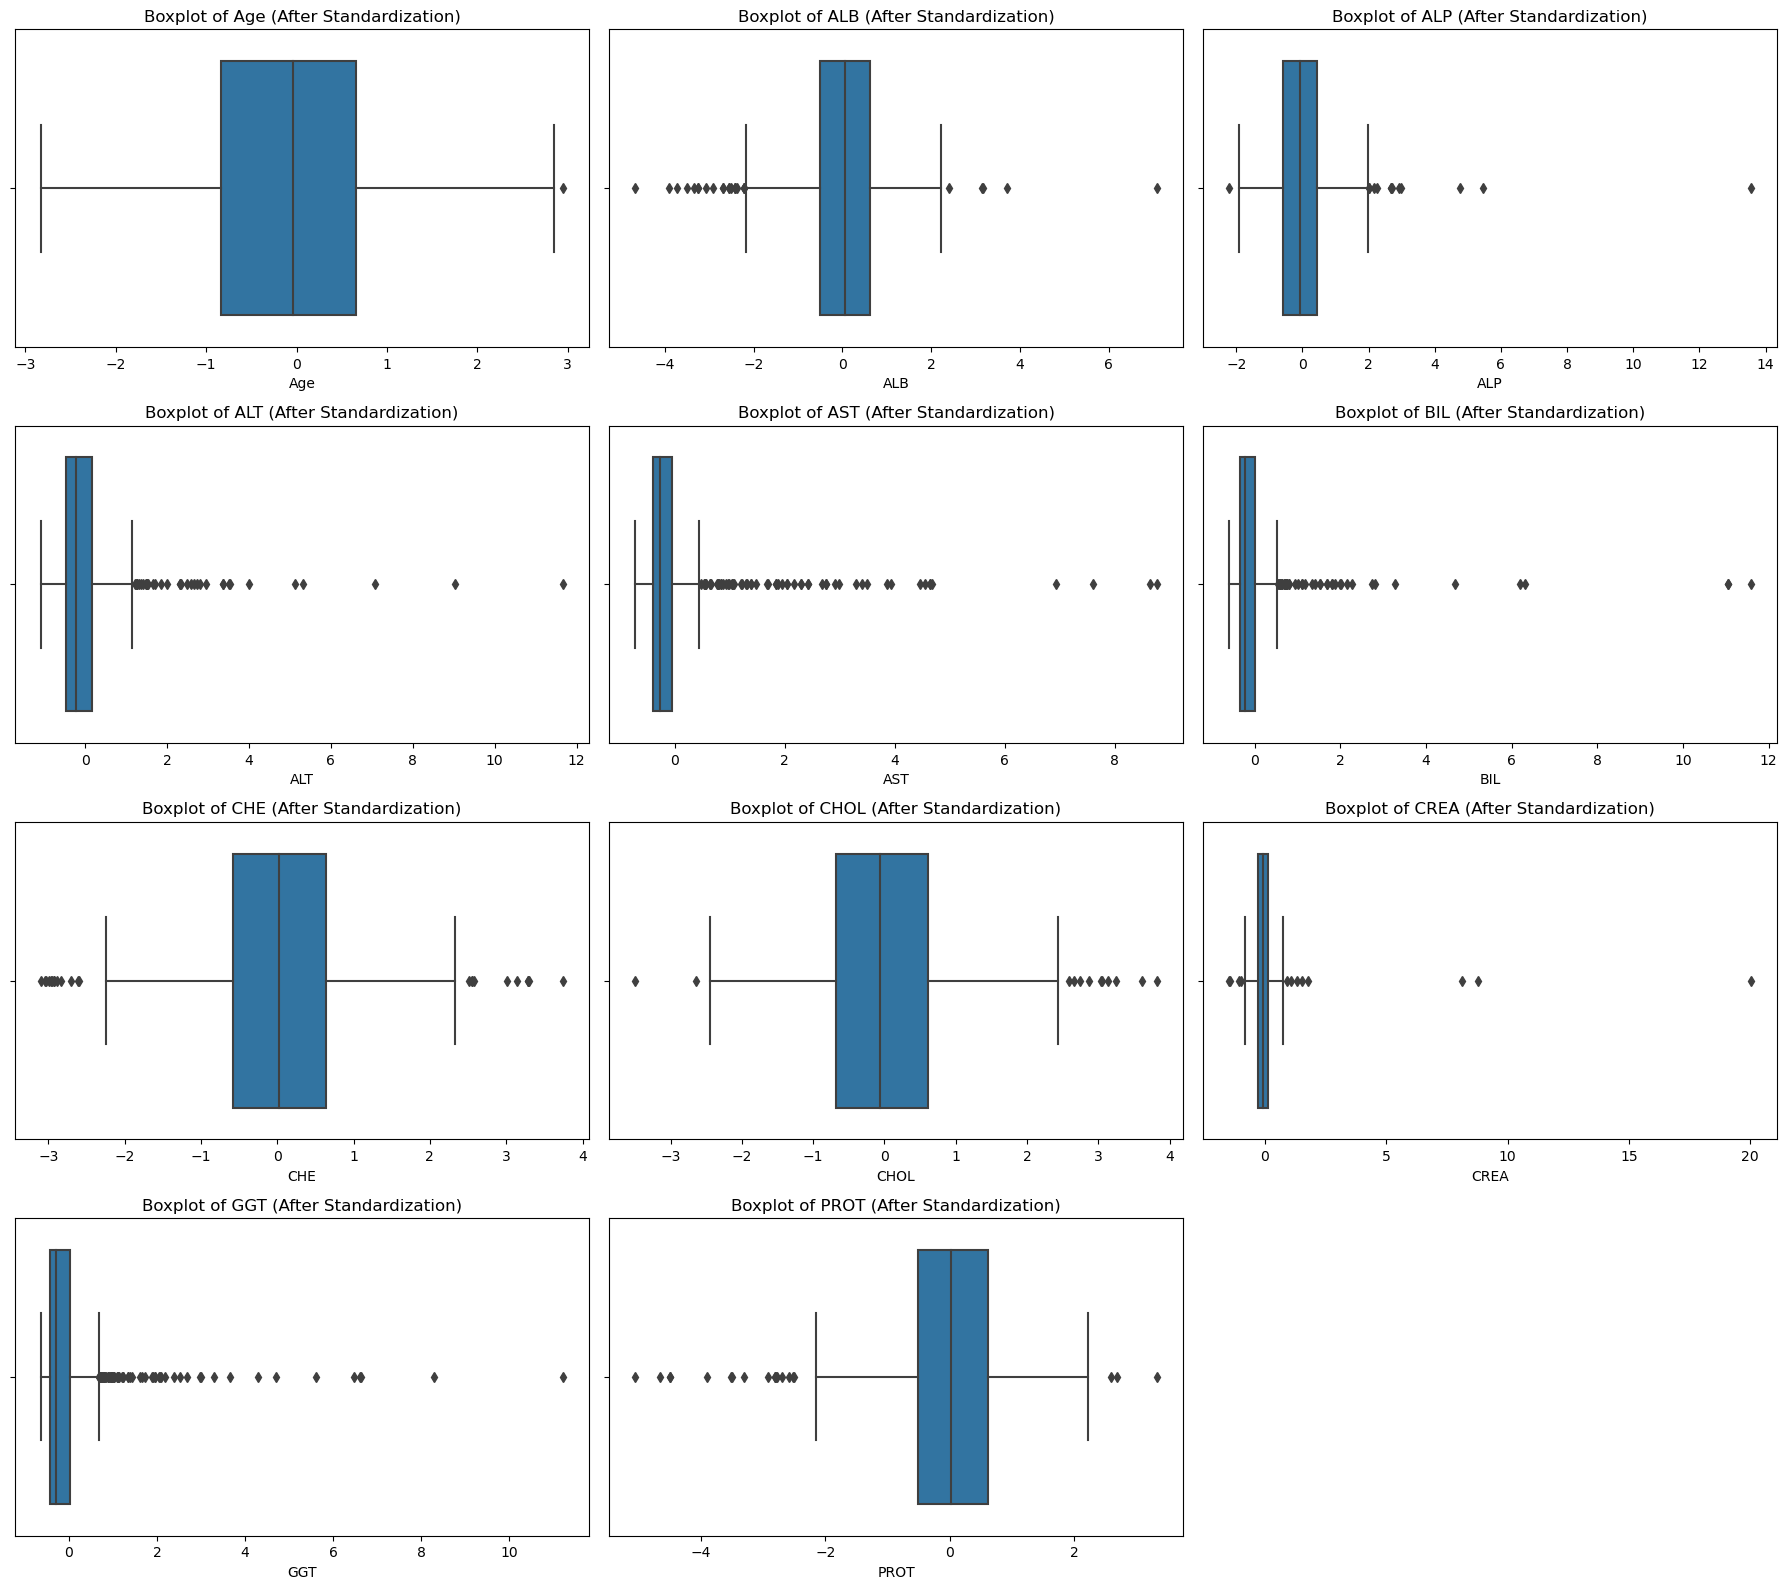

((410, 11), (202, 11), (410,), (202,))

In [19]:
# Separar las variables regresoras y la variable objetivo
X = regressor_vars
y = df['target']

# Mostrar boxplots antes de la estandarización
fig, axes = plt.subplots(num_rows, 3, figsize=(18, 4 * num_rows))
axes = axes.flatten()

for i, col in enumerate(X.columns):
    sns.boxplot(data=X, x=col, ax=axes[i])
    axes[i].set_title(f'Boxplot of {col} (Before Standardization)')
    axes[i].set_xlabel(col)

# Remover subplots vacíos
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

# Aplicar la estandarización a las variables regresoras
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

# Mostrar boxplots después de la estandarización
fig, axes = plt.subplots(num_rows, 3, figsize=(18, 4 * num_rows))
axes = axes.flatten()

for i, col in enumerate(X_scaled.columns):
    sns.boxplot(data=X_scaled, x=col, ax=axes[i])
    axes[i].set_title(f'Boxplot of {col} (After Standardization)')
    axes[i].set_xlabel(col)

# Remover subplots vacíos
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

# Realizar la segmentación de la muestra en 67% para entrenamiento y 33% para prueba
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.33, random_state=42)

# Mostrar las dimensiones de los conjuntos de entrenamiento y prueba
X_train.shape, X_test.shape, y_train.shape, y_test.shape


<div style="color: purple; font-size: 1em;">
Antes de la estandarización, las variables tenían escalas muy diferentes, lo que hacía que algunas como ALT, AST, y GGT mostraran más variabilidad y muchos outliers. Esto podría afectar el rendimiento de los modelos que dependen de las distancias y gradientes.

Después de la estandarización, las variables tienen una media de 0 y una desviación estándar de 1, lo que hace que las escalas sean más uniformes. Aunque los outliers no desaparecen, esta transformación facilita que los modelos converjan mejor y ayuda a interpretar los coeficientes en modelos lineales como la regresión logística.

En cuanto a la segmentación de la muestra, se dividió el 67% de los datos para el entrenamiento y el 33% para la prueba, lo cual permite un buen balance entre ajustar el modelo y validarlo. La proporción de casos positivos y negativos se mantiene constante en ambos conjuntos gracias a la división estratificada.
</div>

### 2. Desarrolla un modelo regresión logística con validación cruzada usando 5-fold, con regularización Elastic Net. Busca para los siguientes hiper parámetros:
#### ● Cs: valores entre 0.01 y 5.0, con 200 valores lineales.
#### ● l1_ratio: valores entre 0 y 1, con 200 valores lineales.
### Muestra los valores óptimos encontrados, y las métricas precisión, recall, f1-score y accuracy. Describe cuáles son las tres características con mayor incidencia en la predicción de sujeto o muestra con sangre con posible enfermedad.

In [20]:
# Definir la lista de hiperparámetros para la búsqueda de grilla
param_grid = {
    'C': np.linspace(0.01, 5.0, 200),
    'l1_ratio': np.linspace(0, 1, 200)
}

# Inicializar el modelo de regresión logística con regularización Elastic Net
log_reg_elastic = LogisticRegression(penalty='elasticnet', solver='saga', max_iter=5000)

# Configurar la búsqueda de grilla con validación cruzada 5-fold
grid_search = GridSearchCV(log_reg_elastic, param_grid, cv=5, scoring='f1', n_jobs=-1)

# Ajustar el modelo a los datos de entrenamiento
grid_search.fit(X_train, y_train)

# Obtener los mejores hiperparámetros encontrados
best_params = grid_search.best_params_

# Realizar predicciones en el conjunto de prueba
y_pred = grid_search.predict(X_test)

# Calcular las métricas de rendimiento
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

# Obtener los coeficientes del modelo ajustado
coef_importance = pd.Series(grid_search.best_estimator_.coef_[0], index=X_train.columns).abs().sort_values(ascending=False)

# Mostrar los resultados
print("Mejores Hiperparámetros:", best_params)
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-Score:", f1)
print("Características más importantes:\n", coef_importance.head(3))

Mejores Hiperparámetros: {'C': 1.1634673366834172, 'l1_ratio': 0.0}
Accuracy: 0.9405940594059405
Precision: 0.95
Recall: 0.6333333333333333
F1-Score: 0.7599999999999999
Características más importantes:
 GGT    1.717394
AST    1.413846
ALP    1.255179
dtype: float64


<div style="color: purple; font-size: 1em;">
El modelo de regresión logística usa una regularización suave, lo que significa que no reduce demasiado los coeficientes de las variables. Esto permite capturar mejor las relaciones entre las variables.

El modelo tiene una buena precisión del 95%, lo que significa que identifica correctamente la mayoría de los casos positivos. Sin embargo, su recall es más bajo (63.3%), lo que indica que se le escapan algunos casos positivos. Esto puede ser porque el modelo prioriza evitar falsos positivos, incluso si pierde algunos casos verdaderos.

Las variables más importantes para el modelo son GGT, AST, y ALP, todas relacionadas con el daño hepático. La GGT es especialmente relevante en enfermedades hepáticas asociadas al alcohol, mientras que AST y ALP también indican problemas en el hígado, como obstrucciones o daño celular.

En resumen, el modelo funciona bien para identificar correctamente los casos positivos, pero podría mejorar en la detección de todos los casos. Se podrían considerar ajustes o técnicas adicionales para captar más casos verdaderos y mejorar el recall.
</div>

### 3. Implementa un modelo Extreme Gradient Boosting con búsqueda de hiper parámetros de grilla, con regularización para la combinación L1 y L2. Considera para esto:

a. reg_lambda: valores entre 0.0 y 2.0, con 10 valores lineales.

b. reg_alpha: valores entre 0 y 1, con 10 valores lineales.

c. learning_rate: valores entre 0.1 a 10, con 20 valores lineales.

In [22]:
# Definir el clasificador XGBoost
xgb_clf = xgb.XGBClassifier(eval_metric='logloss', random_state=42)

# Definir la grilla de hiperparámetros
param_grid_xgb = {
    'reg_lambda': np.linspace(0.0, 2.0, 10),
    'reg_alpha': np.linspace(0.0, 1.0, 10),
    'learning_rate': np.linspace(0.1, 10.0, 20)
}

# Configurar la búsqueda de grilla con validación cruzada 5-fold
grid_search_xgb = GridSearchCV(
    estimator=xgb_clf,
    param_grid=param_grid_xgb,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

# Ajustar el modelo a los datos de entrenamiento
grid_search_xgb.fit(X_train, y_train)

# Obtener los mejores hiperparámetros encontrados
best_params_xgb = grid_search_xgb.best_params_

# Realizar predicciones en el conjunto de prueba
y_pred_xgb = grid_search_xgb.predict(X_test)

# Calcular las métricas de rendimiento
accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
precision_xgb = precision_score(y_test, y_pred_xgb)
recall_xgb = recall_score(y_test, y_pred_xgb)
f1_xgb = f1_score(y_test, y_pred_xgb)

# Obtener la importancia de los atributos
feature_importance = pd.Series(grid_search_xgb.best_estimator_.feature_importances_, index=X_train.columns).sort_values(ascending=False)

# Mostrar los resultados
print("Mejores Hiperparámetros:", best_params_xgb)
print("Accuracy:", accuracy_xgb)
print("Precision:", precision_xgb)
print("Recall:", recall_xgb)
print("F1-Score:", f1_xgb)
print("Importancia de los Atributos:\n", feature_importance.head(3))



Mejores Hiperparámetros: {'learning_rate': 0.6210526315789474, 'reg_alpha': 0.3333333333333333, 'reg_lambda': 0.8888888888888888}
Accuracy: 0.9801980198019802
Precision: 0.9333333333333333
Recall: 0.9333333333333333
F1-Score: 0.9333333333333333
Importancia de los Atributos:
 AST     0.631070
ALT     0.120929
CHOL    0.075425
dtype: float32


<div style="color: purple; font-size: 1em;">

El modelo de XGBoost tiene buenos ajustes para aprender rápido y captar las relaciones entre las variables. Esto ayuda a que el modelo sea más preciso, logrando predecir correctamente en casi todos los casos (98%). Además, logra un equilibrio entre identificar correctamente los casos positivos y evitar errores, con un recall y una precisión del 93.3%.

Las variables más importantes para el modelo son AST, ALT y CHOL. La AST es la más relevante, ya que indica fuertemente la presencia de una enfermedad hepática, mientras que ALT y CHOL también contribuyen, aunque en menor medida.

En resumen, este modelo de XGBoost es muy efectivo para detectar enfermedades hepáticas, ya que no solo tiene un buen rendimiento general, sino que también es capaz de encontrar la mayoría de los casos positivos, lo cual es esencial en aplicaciones médicas.
</div>

### 4. Muestra el nivel de importancia de los atributos, los valores óptimos de los hiper parámetros y las métricas precisión, recall, f1-score y accuracy. Compara los resultados de este modelo con el de regresión logística.

<div style="color: purple; font-size: 1em;">
El modelo de XGBoost tuvo un mejor rendimiento que la regresión logística en este análisis. Aunque la regresión logística fue un poco más precisa al identificar correctamente los casos positivos (95% frente a 93.3%), XGBoost logró detectar muchos más casos verdaderamente positivos, con un recall mucho más alto (93.3% frente a 63.3%). Esto es importante en situaciones médicas, ya que es clave encontrar la mayor cantidad posible de casos con la enfermedad.

En cuanto a las características importantes para los modelos, ambos coinciden en que la AST es la más relevante. Sin embargo, XGBoost logra captar mejor las relaciones complejas entre las variables, mostrando también la influencia de ALT y CHOL, mientras que la regresión logística se enfoca más en GGT y ALP.

En resumen, XGBoost no solo detecta más casos positivos sino que también entiende mejor cómo se relacionan las variables con la enfermedad, por lo que sería la opción más efectiva para este tipo de análisis. La regresión logística sigue siendo útil para entender de manera simple la relación de cada variable con la predicción, pero no captura los casos tan bien como XGBoost.
</div>

<div style="color: green; text-align: center; font-size: 3em;">
    <strong>Fin 😌🩸</strong>
</div>